In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib

In [3]:
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data" / "processed"

history = pd.read_csv(DATA_DIR / "carbon_intensity.csv")

print("Dataset shape:", history.shape)
print(history.columns.tolist())
display(history.head())

Dataset shape: (38976, 8)
['provider', 'region', 'timestamp', 'carbon_intensity_gco2_kwh', 'renewable_percentage', 'hour', 'day_of_week', 'month']


,provider,region,timestamp,carbon_intensity_gco2_kwh,renewable_percentage,hour,day_of_week,month
0,aws,af-south-1,2026-08-19 00:53:00.211592+00:00,795.6,5.0,0,2,8
1,aws,af-south-1,2026-08-19 02:17:53.174894+00:00,795.6,5.0,2,2,8
2,aws,af-south-1,2026-08-19 03:42:26.812833+00:00,780.0,8.0,3,2,8
3,aws,af-south-1,2026-08-19 04:34:02.547742+00:00,780.0,8.0,4,2,8
4,aws,af-south-1,2026-08-19 05:25:46.493498+00:00,780.0,8.0,5,2,8


In [4]:
history["timestamp"] = pd.to_datetime(history["timestamp"])

history = history.sort_values(
    ["provider", "region", "timestamp"]
).copy()

history["carbon_lag_1"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(1)

history["carbon_lag_2"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(2)

history["carbon_lag_3"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(3)

history = history.dropna(
    subset=["carbon_lag_1", "carbon_lag_2", "carbon_lag_3"]
)

history["hour"] = history["timestamp"].dt.hour
history["day_of_week"] = history["timestamp"].dt.dayofweek
history["month"] = history["timestamp"].dt.month

print("Training dataset shape:", history.shape)

Training dataset shape: (38628, 11)


In [5]:
history["timestamp"] = pd.to_datetime(history["timestamp"])

history = history.sort_values(
    ["provider", "region", "timestamp"]
).copy()

history["carbon_lag_1"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(1)

history["carbon_lag_2"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(2)

history["carbon_lag_3"] = history.groupby(
    ["provider", "region"]
)["carbon_intensity_gco2_kwh"].shift(3)

history = history.dropna(
    subset=["carbon_lag_1", "carbon_lag_2", "carbon_lag_3"]
)

history["hour"] = history["timestamp"].dt.hour
history["day_of_week"] = history["timestamp"].dt.dayofweek
history["month"] = history["timestamp"].dt.month

print("Training dataset shape:", history.shape)

Training dataset shape: (38280, 11)


In [6]:
features = [
    "renewable_percentage",
    "hour",
    "day_of_week",
    "month",
    "carbon_lag_1",
    "carbon_lag_2",
    "carbon_lag_3"
]

target = "carbon_intensity_gco2_kwh"

history = history.sort_values("timestamp")

split_index = int(len(history) * 0.8)

X_train = history[features].iloc[:split_index]
X_test = history[features].iloc[split_index:]

y_train = history[target].iloc[:split_index]
y_test = history[target].iloc[split_index:]

model = RandomForestRegressor(
    n_estimators=100,
    max_depth=12,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))
r2 = r2_score(y_test, predictions)

print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 16.328
RMSE: 37.717
R2 Score: 0.96


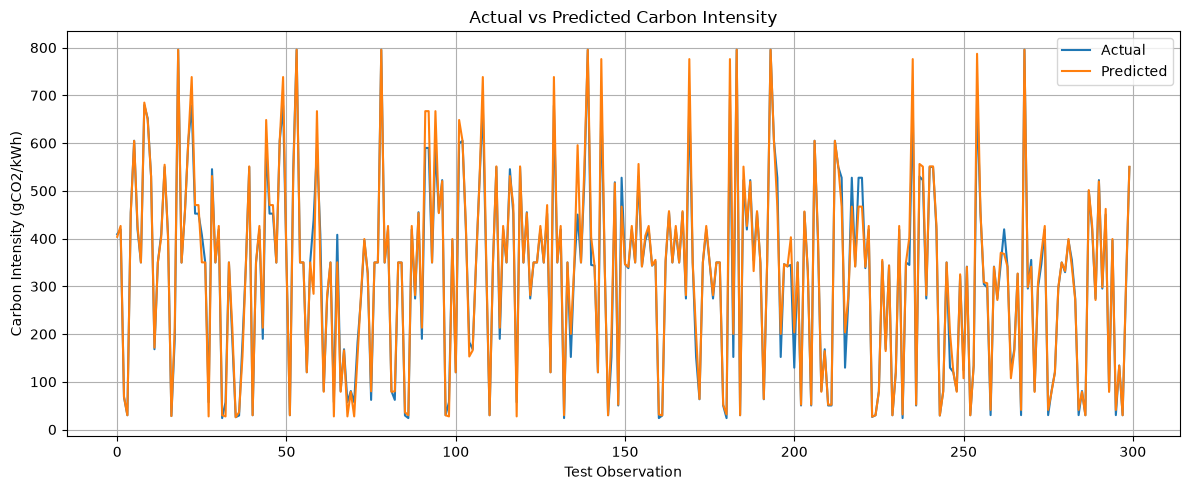

In [8]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_test.iloc[:300].to_numpy(),
    label="Actual"
)

plt.plot(
    predictions[:300],
    label="Predicted"
)

plt.title("Actual vs Predicted Carbon Intensity")
plt.xlabel("Test Observation")
plt.ylabel("Carbon Intensity (gCO2/kWh)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [9]:
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 16.328
RMSE: 37.717
R2 Score: 0.96


In [10]:
MODEL_DIR = BASE_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(model, MODEL_DIR / "carbon_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [11]:
print("MAE:", round(mae, 3))
print("RMSE:", round(rmse, 3))
print("R2 Score:", round(r2, 3))

MAE: 16.328
RMSE: 37.717
R2 Score: 0.96


In [1]:
import sys
from pathlib import Path

BASE_DIR = Path.cwd().parent
sys.path.insert(0, str(BASE_DIR / "src" / "cloudsim"))

from carbon_prediction import predict_latest_carbon

prediction = predict_latest_carbon(
    provider="aws",
    region="ap-south-1"
)

print("Predicted carbon intensity:", round(prediction, 2), "gCO2/kWh")

Predicted carbon intensity: 412.5 gCO2/kWh


In [2]:
from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd().parent

region_config = pd.read_csv(
    BASE_DIR / "data" / "preprocessed" / "region_config.csv"
)

print(region_config.columns.tolist())

display(
    region_config[
        ["provider", "region", "pes", "mips_per_pe", "ram_mb",
         "idle_power_w", "max_power_w", "pue", "cost_per_hour"]
    ].head()
)

['datacenter_id', 'provider', 'region', 'host_id', 'pes', 'mips_per_pe', 'ram_mb', 'storage_mb', 'bandwidth_mbps', 'idle_power_w', 'max_power_w', 'pue', 'cost_per_hour']


,provider,region,pes,mips_per_pe,ram_mb,idle_power_w,max_power_w,pue,cost_per_hour
0,aws,af-south-1,4,800,8192,130,262,1.2,0.085
1,aws,af-south-1,8,1000,16384,160,324,1.2,0.090
2,aws,af-south-1,8,1200,16384,162,326,1.2,0.095
3,aws,af-south-1,12,1500,24576,192,388,1.2,0.100
4,aws,af-south-1,16,2000,32768,222,450,1.2,0.105


In [3]:
import sys
from pathlib import Path

BASE_DIR = Path.cwd().parent
sys.path.insert(0, str(BASE_DIR / "src" / "cloudsim"))

from scheduler import select_best_region

test_candidates = pd.DataFrame({
    "provider": ["aws", "aws", "aws"],
    "region": ["ap-south-1", "eu-west-1", "us-east-1"],
    "predicted_carbon": [412.5, 180.0, 300.0],
    "estimated_energy_kwh": [0.5, 0.6, 0.4],
    "estimated_cost": [2.0, 2.5, 1.5],
})

ranked = select_best_region(test_candidates)

display(ranked)
print("Recommended region:", ranked.iloc[0]["region"])

,provider,region,predicted_carbon,estimated_energy_kwh,estimated_cost,predicted_carbon_normalized,estimated_energy_kwh_normalized,estimated_cost_normalized,score
0,aws,us-east-1,300.0,0.4,1.5,0.516129,0.0,0.0,0.309677
1,aws,eu-west-1,180.0,0.6,2.5,0.000000,1.0,1.0,0.400000
2,aws,ap-south-1,412.5,0.5,2.0,1.000000,0.5,0.5,0.800000


Recommended region: us-east-1


In [4]:
from pathlib import Path

BASE_DIR = Path.cwd().parent

files_to_check = [
    BASE_DIR / "data" / "processed" / "carbon_intensity.csv",
    BASE_DIR / "data" / "processed" / "region_config.csv",
    BASE_DIR / "data" / "processed" / "workload.csv",
    BASE_DIR / "models" / "carbon_model.pkl",
]

for file in files_to_check:
    print(f"{file.name}: {'Found' if file.exists() else 'MISSING'}")

carbon_intensity.csv: Found
region_config.csv: Found
workload.csv: Found
carbon_model.pkl: Found


In [5]:
import joblib

model_path = BASE_DIR / "models" / "carbon_model.pkl"
model = joblib.load(model_path)

print("Model loaded successfully!")
print("Expected features:", model.n_features_in_)
print("Feature names:", model.feature_names_in_)

Model loaded successfully!
Expected features: 7
Feature names: ['renewable_percentage' 'hour' 'day_of_week' 'month' 'carbon_lag_1'
 'carbon_lag_2' 'carbon_lag_3']


In [2]:

from pathlib import Path
import pandas as pd
import numpy as np
import joblib

# Project root = parent of the notebooks folder
BASE_DIR = Path.cwd().parent

# Load processed carbon data
carbon_path = BASE_DIR / "data" / "processed" / "carbon_intensity.csv"
carbon_df = pd.read_csv(carbon_path)

print("Dataset shape:", carbon_df.shape)
print("Columns:", carbon_df.columns.tolist())
display(carbon_df.head())

print("\nMissing values:")
print(carbon_df.isnull().sum())


Dataset shape: (38976, 8)
Columns: ['provider', 'region', 'timestamp', 'carbon_intensity_gco2_kwh', 'renewable_percentage', 'hour', 'day_of_week', 'month']


,provider,region,timestamp,carbon_intensity_gco2_kwh,renewable_percentage,hour,day_of_week,month
0,aws,af-south-1,2026-08-19 00:53:00.211592+00:00,795.6,5.0,0,2,8
1,aws,af-south-1,2026-08-19 02:17:53.174894+00:00,795.6,5.0,2,2,8
2,aws,af-south-1,2026-08-19 03:42:26.812833+00:00,780.0,8.0,3,2,8
3,aws,af-south-1,2026-08-19 04:34:02.547742+00:00,780.0,8.0,4,2,8
4,aws,af-south-1,2026-08-19 05:25:46.493498+00:00,780.0,8.0,5,2,8



Missing values:
provider                     0
region                       0
timestamp                    0
carbon_intensity_gco2_kwh    0
renewable_percentage         0
hour                         0
day_of_week                  0
month                        0
dtype: int64
